# Experiment 1b — Full-book scan: does the awakening detector catch new mules?

**Question:** business has identified 3 new mule accounts. Without changing any rule, does `burst_on_wake` flag them,
how high do they rank, and how many accounts does the detector flag across the whole book?

**Why this test matters:** every threshold in Experiment 1 was set while looking at the original 10 mules. These 3 were
never seen, so this is the detector's first out-of-sample test. The rules below are **frozen before looking**:

| Rule | Frozen value |
|---|---|
| Active day | customer turnover ≥ \$100 |
| Awakening | start of the first run (split at ≥ 14 silent days) carrying ≥ 30% of window turnover |
| `burst_on_wake` | first 14 days: ≥ \$50k turnover, in/out match ≥ 0.5, ≥ 3 active days |
| Also reported | the same at ≥ \$100k (named as the better trade-off before this test) |

**Success looks like** (decided before running): at least 2 of the 3 new mules flagged at \$50k, and a book-wide flag rate
close to the ~5% seen in the 200-account sample. Do not tune thresholds after seeing the 3 — that would turn the test back
into an in-sample fit.

**Scope and safety:** read-only, separate from `aml_screening.py` and from `mule_early_signals.ipynb`. Same population as
production (USD, opened since 2024-01-01, closed accounts included). Transactions are pulled per opening month and cached;
Finacle is only queried for months that are missing or still filling in. Outputs go to `outputs/early_signals_scan/`.

**How to run:** fill in `NEW_MULES` (ACIDs or account numbers), optionally `IDENTIFIED_ON`, set `SYNTHETIC = False`, run all.

In [1]:
import os, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SYNTHETIC = False                 # False = real data

# The 3 accounts business identified: ACID or account number (FORACID), as given
NEW_MULES = ["UG6302468", "UG6300154", "UG6334629"]
# Optional: date business identified each one, to measure how much earlier the detector would have fired
IDENTIFIED_ON = {"UG6302468": "2026-10-29", "UG6300154": "2026-10-29", "UG6334629": "2026-10-29"}               # e.g. {"UG0000000": "2026-10-20"}

# --- Frozen rules (same as Experiment 1; do not tune after seeing the results) ---
WINDOW_DAYS          = 180
EARLY_DAYS           = 90
ACTIVE_MIN_USD       = 100
RUN_GAP_DAYS         = 14
RUN_SHARE            = 0.30
WAKE_DAYS            = 14
DORMANT_MIN_DAYS     = 30
PRE_WAKE_MAX_SHARE   = 0.05
WAKE_MIN_USD         = 50_000
WAKE_MIN_USD_ALT     = 100_000   # reported alongside, decided before this test
WAKE_MIN_MATCH       = 0.5
WAKE_MIN_ACTIVE_DAYS = 3

# --- Cache ---
POPULATION_MAX_AGE_DAYS = 7
REFRESH_POPULATION = False
REFRESH_ALL        = False

AS_OF = pd.Timestamp.today().normalize()
OUT = Path("outputs/early_signals_scan"); OUT.mkdir(parents=True, exist_ok=True)
CACHE_DIR = Path("cache/early_signals_scan" + ("_synthetic" if SYNTHETIC else "")); CACHE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 250, "display.max_columns", 40, "display.max_colwidth", 60)

## 1. Connections and queries

In [2]:
ENV_FILE = ".env"
try:
    from dotenv import load_dotenv
    load_dotenv(ENV_FILE, override=False)
except ImportError:
    print("python-dotenv not installed; relying on variables already in the environment")

def _engine(prefix):
    '''Copied from aml_screening.py. READ = Finacle, WRITE = reporting DB (SELECTs only here).'''
    from sqlalchemy import create_engine, URL
    full_url = os.environ.get(f"AML_{prefix}_URL")
    if full_url:
        return create_engine(full_url, fast_executemany=True)
    def req(name):
        val = os.environ.get(f"AML_{prefix}_{name}")
        if not val:
            raise RuntimeError(f"Set AML_{prefix}_{name} (or provide a full AML_{prefix}_URL)")
        return val
    url = URL.create("mssql+pyodbc", username=req("USER"), password=req("PWD"), host=req("HOST"),
                     port=int(os.environ.get(f"AML_{prefix}_PORT", "1433")), database=req("DB"),
                     query={"driver": os.environ.get("AML_ODBC_DRIVER", "ODBC Driver 17 for SQL Server")})
    return create_engine(url, fast_executemany=True)

_fin = _rep = None
def fin():
    global _fin, _rep
    if _fin is None:
        _fin, _rep = _engine("READ"), _engine("WRITE")
    return _fin
def rep():
    fin(); return _rep

FIN = "RSVRRealtimeFinacleUGPRD.TBAADM"

# Whole screened population: master only, no transaction scan, so it is quick
POPULATION_SQL = f'''
SELECT ACID, FORACID, ACCT_NAME, CIF_ID, ACCT_OPN_DATE, ACCT_CLS_FLG
FROM {FIN}.GENERAL_ACCT_MAST_TABLE
WHERE ACCT_CRNCY_CODE = 'USD' AND ACCT_OPN_DATE >= '2024-01-01'
'''

# Transactions of the accounts opened in one calendar month, first WINDOW_DAYS days of life only
MONTH_TXN_SQL = f'''
SELECT hd.ACID, gm.ACCT_OPN_DATE, hd.TRAN_DATE, hd.TRAN_AMT, hd.PART_TRAN_TYPE, hd.RPT_CODE, hd.TRAN_PARTICULAR
FROM {FIN}.HIST_TRAN_DTL_TABLE hd
JOIN {FIN}.GENERAL_ACCT_MAST_TABLE gm ON hd.ACID = gm.ACID
WHERE gm.ACCT_CRNCY_CODE = 'USD'
  AND gm.ACCT_OPN_DATE >= '{{start}}' AND gm.ACCT_OPN_DATE < '{{end}}'
  AND hd.TRAN_DATE < DATEADD(day, {{window}}, gm.ACCT_OPN_DATE)
'''

## 2. Synthetic book (dry-run only)

In [3]:
def make_synthetic_book(n=3000, seed=11):
    '''A fake book with the production column names: 10 old reference mules, 3 new mules, ordinary accounts.
    Not evidence of anything.'''
    rng = np.random.default_rng(seed)
    accts, rows = [], []

    def add(acid, opn, day, amt, ptt, part="TRF", rpt=None):
        rows.append(dict(ACID=acid, ACCT_OPN_DATE=opn, TRAN_DATE=opn + pd.Timedelta(days=int(day)),
                         TRAN_AMT=round(float(amt), 2), PART_TRAN_TYPE=ptt, RPT_CODE=rpt, TRAN_PARTICULAR=part))
    def charges(acid, opn, upto):
        for d in range(30, upto, 30):
            add(acid, opn, d, rng.uniform(8, 25), "D", "MAINTENANCE CHARGE", "CHG")
    def burst(acid, opn, start, span=25, k=12, lo=5_000, hi=60_000, out=0.95):
        for _ in range(k):
            d = start + rng.integers(0, span); amt = rng.uniform(lo, hi)
            add(acid, opn, d, amt, "C", f"INWARD TT {rng.integers(100, 999)}")
            add(acid, opn, d + rng.integers(0, 2), amt * rng.uniform(out - 0.05, out), "D", "OUTWARD TT")
    def dormant_burst(acid, opn, noise=False):
        sd = rng.integers(1, 10); add(acid, opn, sd, rng.uniform(100, 900), "C", "CASH DEPOSIT")
        wake = sd + rng.integers(40, 110); charges(acid, opn, wake)
        if noise:
            for dd in range(sd + 9, wake, 9):
                add(acid, opn, dd, rng.uniform(1, 20), rng.choice(["C", "D"]), "SMALL ADJ")
        burst(acid, opn, wake, span=rng.choice([25, 90]))
    def slow_out(acid, opn):                     # takes money in first, pays out weeks later
        d0 = rng.integers(2, 10)
        for _ in range(8):
            add(acid, opn, d0 + rng.integers(0, 12), rng.uniform(20_000, 50_000), "C", "INWARD TT")
        for _ in range(8):
            add(acid, opn, d0 + 20 + rng.integers(0, 20), rng.uniform(20_000, 50_000), "D", "OUTWARD TT")
    def business(acid, opn):
        for d in sorted(rng.integers(0, 400, rng.integers(10, 120))):
            add(acid, opn, d, rng.uniform(100, 15_000), rng.choice(["C", "D"], p=[.52, .48]), "INVOICE")
        charges(acid, opn, 400)
        if rng.random() < .3:
            add(acid, opn, rng.integers(5, 200), rng.uniform(100, 900), "C", "AC XFR FROM GL 0603 ADJ")
    def dormant(acid, opn):
        add(acid, opn, rng.integers(0, 20), rng.uniform(50, 1500), "C", "CASH DEPOSIT"); charges(acid, opn, 400)
    def big_legit(acid, opn):                    # one-off large business event
        d = rng.integers(0, 60); amt = rng.uniform(100_000, 2_000_000)
        add(acid, opn, d, amt, "C", "COMPANY DIVIDEND")
        for j in range(3):
            add(acid, opn, d + 2 + 3 * j, amt / 3.2, "D", "PAYMNT OF INVOICES")
    def single_pair(acid, opn):
        d = rng.integers(10, 120); amt = rng.uniform(1e6, 5e7)
        add(acid, opn, d, amt, "C", "INWARD TT"); add(acid, opn, d, amt, "D", "OUTWARD TT")

    for i in range(n):
        acid = f"UG{i:07d}"
        opn = pd.Timestamp("2024-01-01") + pd.Timedelta(days=int(rng.integers(0, (AS_OF - pd.Timestamp('2024-01-01')).days - 5)))
        if i == 0:   kind, name = dormant_burst, "SYNTHETIC NEW MULE A"
        elif i == 1: kind, name = (lambda a, o: burst(a, o, rng.integers(2, 10), span=60, k=20)), "SYNTHETIC NEW MULE B"
        elif i == 2: kind, name = slow_out, "SYNTHETIC NEW MULE C"
        elif i < 13: kind, name = (dormant_burst if i < 7 else (lambda a, o: burst(a, o, rng.integers(0, 15)))), f"SYNTHETIC OLD REF {i:02d}"
        else:
            r = rng.random(); name = f"SYNTHETIC ACCOUNT {i:05d}"
            kind = (business if r < .70 else dormant if r < .88 else big_legit if r < .93 else single_pair if r < .95
                    else (lambda a, o: dormant_burst(a, o, noise=True)))
        kind(acid, opn)
        accts.append(dict(ACID=acid, FORACID=f"9{i:09d}", ACCT_NAME=name, CIF_ID=f"C{i:07d}",
                          ACCT_OPN_DATE=opn, ACCT_CLS_FLG="N"))
    master = pd.DataFrame(accts)
    tx = pd.DataFrame(rows)
    tx = tx[(tx.TRAN_DATE <= AS_OF) & (tx.TRAN_DATE < tx.ACCT_OPN_DATE + pd.Timedelta(days=WINDOW_DAYS))]
    return master, tx, master.ACID.iloc[3:13].tolist()

## 3. Load — cache first, Finacle only when needed

| data | pulled from Finacle when… |
|---|---|
| population (account master, quick) | no cache yet, older than `POPULATION_MAX_AGE_DAYS`, or `REFRESH_POPULATION` |
| transactions, one file per opening month | that month isn't cached yet, or some of its accounts were younger than `WINDOW_DAYS` when it was pulled (so their window was still filling in) |
| watchlist | every run (small query) |

The first real run pulls every month once (about 34 queries, the slow part). Later runs only refresh the last ~6 months.
`REFRESH_ALL = True` ignores the cache.

In [4]:
def _load(name):
    p = CACHE_DIR / f"{name}.pkl"
    return pd.read_pickle(p) if p.exists() and not REFRESH_ALL else None
def _save(name, df):
    df.to_pickle(CACHE_DIR / f"{name}.pkl")

if SYNTHETIC:
    syn_master, syn_tx, syn_watch = make_synthetic_book()

queries = []

# watchlist (always live)
watchlist = (list(syn_watch) if SYNTHETIC else
             pd.read_sql("SELECT acid FROM aml_watchlist WHERE active = 1", rep())["acid"].tolist())

# population
population, meta = _load("population"), _load("population_meta")
age = (AS_OF - meta.fetched_on.iloc[0]).days if meta is not None else None
if population is None or REFRESH_POPULATION or age is None or age > POPULATION_MAX_AGE_DAYS:
    population = syn_master.copy() if SYNTHETIC else pd.read_sql(POPULATION_SQL, fin())
    population["ACCT_OPN_DATE"] = pd.to_datetime(population.ACCT_OPN_DATE)
    _save("population", population); _save("population_meta", pd.DataFrame({"fetched_on": [AS_OF]}))
    queries.append(f"population: {len(population):,} accounts"); age = 0

# transactions by opening month
months = pd.period_range(population.ACCT_OPN_DATE.min().to_period("M"), AS_OF.to_period("M"), freq="M")
index = _load("month_index")
index = index if index is not None else pd.DataFrame(columns=["month", "fetched_on", "window"])
idx = index.set_index("month")

def month_is_stale(m):
    if str(m) not in idx.index:
        return True
    r = idx.loc[str(m)]
    still_filling = (r.fetched_on - m.start_time).days < r.window      # youngest account in that month was inside its window
    return r.window < WINDOW_DAYS or (still_filling and r.fetched_on < AS_OF)

parts, pulled = [], []
for m in months:
    f = CACHE_DIR / f"txns_{m}.pkl"
    if not f.exists() or month_is_stale(m) or REFRESH_ALL:
        start, end = m.start_time, (m + 1).start_time
        if SYNTHETIC:
            t = syn_tx[(syn_tx.ACCT_OPN_DATE >= start) & (syn_tx.ACCT_OPN_DATE < end)].copy()
        else:
            t = pd.read_sql(MONTH_TXN_SQL.format(start=start.strftime("%Y-%m-%d"), end=end.strftime("%Y-%m-%d"),
                                                 window=WINDOW_DAYS), fin())
        t.to_pickle(f); pulled.append(str(m))
        index = pd.concat([index[index.month != str(m)],
                           pd.DataFrame({"month": [str(m)], "fetched_on": [AS_OF], "window": [WINDOW_DAYS]})],
                          ignore_index=True)
    parts.append(pd.read_pickle(f))
_save("month_index", index)
raw = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()
if pulled:
    queries.append(f"transactions: {len(pulled)} month(s) ({pulled[0]} … {pulled[-1]}), {sum(len(pd.read_pickle(CACHE_DIR / f'txns_{m}.pkl')) for m in pulled):,} rows")

print("Finacle queries this run:", "; ".join(queries) if queries else "none — everything served from cache")
print(f"Population: {len(population):,} accounts (cache age {age} day(s)); transactions in use: {len(raw):,}")

/tmp/ipykernel_1739167/1480583300.py:49: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  index = pd.concat([index[index.month != str(m)],


Finacle queries this run: population: 27,447 accounts; transactions: 34 month(s) (2024-01 … 2026-10), 798,320 rows
Population: 27,447 accounts (cache age 0 day(s)); transactions in use: 798,320


## 4. Who is who

In [5]:
pop = population.copy()
ids = {str(x).strip() for x in NEW_MULES}
pop["is_new_mule"] = pop.ACID.astype(str).isin(ids) | pop.FORACID.astype(str).isin(ids)
pop["group"] = np.select([pop.is_new_mule, pop.ACID.isin(watchlist)], ["new mule", "reference"], "other")
pop["observed_days"] = (AS_OF - pop.ACCT_OPN_DATE).dt.days.clip(lower=1, upper=WINDOW_DAYS)

found = set(pop.loc[pop.is_new_mule, "ACID"]) | set(pop.loc[pop.is_new_mule, "FORACID"].astype(str))
missing = [x for x in ids if x not in found]
print(pop.group.value_counts().to_string())
if missing:
    print(f"\nNot in the scanned population (not USD, opened before 2024, or a typo): {missing}")
both = pop[pop.is_new_mule & pop.ACID.isin(watchlist)]
if len(both):
    print(f"\nNote: {len(both)} new mule(s) are already on the watchlist; they are treated as new mules here.")

group
other        27434
reference       10
new mule         3


## 5. Classify and compute the measures for every account

Same rules as Experiment 1: charge = `RPT_CODE` CHG/INT, GL leg = narration matching `GL <digits>`, everything else is
customer activity. The metric code is a vectorised rewrite of `early_metrics()` so the whole book runs in minutes; it was
checked to give identical results account by account.

`first_hit_day` is extra: the first day a nightly detector would have fired — the earliest day within the 14 days after
waking when the turnover, match and active-day conditions are all met so far. `detect_date` turns it into a calendar date.

In [6]:
def classify(df):
    df = df.copy()
    for col in ("TRAN_DATE", "ACCT_OPN_DATE"):
        df[col] = pd.to_datetime(df[col], errors="coerce")
    part = df["TRAN_PARTICULAR"].fillna("").str.upper()
    rpt = df["RPT_CODE"].fillna("").str.upper()
    is_charge = rpt.isin(["CHG", "INT"])
    is_gl = part.str.contains(r"\bGL\s*\d", regex=True)
    df["stream"] = np.select([is_charge, is_gl], ["charge", "gl"], "customer")
    df["dir"] = df["PART_TRAN_TYPE"].str.upper().str.strip().map({"C": "cr", "D": "dr"})
    df["TRAN_AMT"] = df["TRAN_AMT"].astype(float).abs()
    df["day"] = (df["TRAN_DATE"].dt.normalize() - df["ACCT_OPN_DATE"].dt.normalize()).dt.days
    return df

tx = classify(raw)
obs = pop.set_index("ACID").observed_days
tx = tx[(tx.day >= 0) & tx.dir.notna() & (tx.day < tx.ACID.map(obs).fillna(0))]

def scan_metrics(tx, obs):
    cust = tx[tx.stream == "customer"]
    daily = cust.groupby(["ACID", "day", "dir"]).TRAN_AMT.sum().unstack("dir", fill_value=0.0)
    for c in ("cr", "dr"):
        if c not in daily:
            daily[c] = 0.0
    chg = tx[(tx.stream == "charge") & (tx.dir == "dr")].groupby(["ACID", "day"]).TRAN_AMT.sum()
    chg_by = {a: g.droplevel(0) for a, g in chg.groupby(level=0)}
    out = {}
    by_acct = {a: g for a, g in daily.groupby(level=0)}
    empty = np.array([], dtype=float)
    for acid in tx.ACID.unique():                 # every account with any transaction, incl. charges only
        g = by_acct.get(acid)
        days = g.index.get_level_values("day").to_numpy() if g is not None else np.array([], dtype=int)
        cr, dr = (g.cr.to_numpy(), g.dr.to_numpy()) if g is not None else (empty, empty)
        to = cr + dr
        ch = chg_by.get(acid, pd.Series(dtype=float))
        chd, chv = ch.index.to_numpy(), ch.to_numpy()
        total = to.sum(); act = days[to >= ACTIVE_MIN_USD]
        m = {"turnover_window": total, "active_days": len(act)}
        m["first_cr_day"] = days[cr > 0][0] if (cr > 0).any() else np.nan
        m["first_cr_amt"] = cr[cr > 0][0] if (cr > 0).any() else np.nan
        m["first_dr_day"] = days[dr > 0][0] if (dr > 0).any() else np.nan
        m["turnover_first30_share"] = to[days < 30].sum() / total if total else np.nan
        early_ch = chv[chd < EARLY_DAYS].sum(); early_db = early_ch + dr[days < EARLY_DAYS].sum()
        m["charge_share_early"] = early_ch / early_db if early_db else np.nan
        m["longest_quiet"] = int((np.diff(np.concatenate([[-1], act])) - 1).max()) if len(act) else np.nan
        for k in ("awakening_day", "quiet_before_awake", "pre_wake_turnover", "pre_wake_share", "seed_amt",
                  "charges_before_wake", "wake_turnover", "wake_match", "wake_active_days", "first_hit_day"):
            m[k] = np.nan
        m["wake_complete"] = False
        if total and len(act):
            runs = np.split(act, np.flatnonzero(np.diff(act) - 1 >= RUN_GAP_DAYS) + 1)
            shares = [to[(days >= r[0]) & (days <= r[-1])].sum() / total for r in runs]
            big = [i for i, s in enumerate(shares) if s >= RUN_SHARE]
            a = int(runs[big[0] if big else int(np.argmax(shares))][0])
            prior = act[act < a]
            pre, post = days < a, (days >= a) & (days < a + WAKE_DAYS)
            pc, pd_ = cr[post].sum(), dr[post].sum()
            m.update(awakening_day=a, quiet_before_awake=a - (prior[-1] + 1 if len(prior) else 0),
                     pre_wake_turnover=to[pre].sum(), pre_wake_share=to[pre].sum() / total,
                     seed_amt=cr[pre].sum(), charges_before_wake=chv[chd < a].sum(),
                     wake_turnover=pc + pd_, wake_match=min(pc, pd_) / max(pc, pd_) if max(pc, pd_) else np.nan,
                     wake_active_days=int((to[post] >= ACTIVE_MIN_USD).sum()),
                     wake_complete=a + WAKE_DAYS <= obs.get(acid, WINDOW_DAYS))
            # first day a nightly check would have fired
            ccr, cdr = np.cumsum(cr[post]), np.cumsum(dr[post])
            cact = np.cumsum(to[post] >= ACTIVE_MIN_USD)
            mx = np.maximum(ccr, cdr)
            ok = ((ccr + cdr) >= WAKE_MIN_USD) & (np.divide(np.minimum(ccr, cdr), mx, out=np.zeros_like(mx), where=mx > 0)
                                                 >= WAKE_MIN_MATCH) & (cact >= WAKE_MIN_ACTIVE_DAYS)
            if ok.any():
                m["first_hit_day"] = int(days[post][np.argmax(ok)])
        out[acid] = m
    return pd.DataFrame.from_dict(out, orient="index").rename_axis("ACID").reset_index()

import time; t0 = time.time()
metrics = scan_metrics(tx, obs)
scan = pop.merge(metrics, on="ACID", how="left")
scan["has_activity"] = scan.awakening_day.notna()
scan["dormant_start"] = (scan.awakening_day >= DORMANT_MIN_DAYS) & (scan.pre_wake_share <= PRE_WAKE_MAX_SHARE)
shape_ok = (scan.wake_match >= WAKE_MIN_MATCH) & (scan.wake_active_days >= WAKE_MIN_ACTIVE_DAYS)
scan["burst_on_wake"] = shape_ok & (scan.wake_turnover >= WAKE_MIN_USD)
scan["burst_100k"] = shape_ok & (scan.wake_turnover >= WAKE_MIN_USD_ALT)
scan["dormant_then_burst"] = scan.dormant_start & scan.burst_on_wake
scan["detect_date"] = scan.ACCT_OPN_DATE + pd.to_timedelta(scan.first_hit_day, unit="D")
print(f"Measured {len(metrics):,} accounts with customer activity in {time.time() - t0:.0f}s")

Measured 25,841 accounts with customer activity in 13s


## 6. The test — were the new mules caught?

In [7]:
flagged = scan[scan.burst_on_wake & (scan.group == "other")]
rank_pool = scan[scan.burst_on_wake].sort_values("wake_turnover", ascending=False).reset_index(drop=True)
rank_pool["rank"] = np.arange(1, len(rank_pool) + 1)

cols = ["ACCT_NAME", "FORACID", "ACCT_OPN_DATE", "awakening_day", "pre_wake_share", "wake_turnover", "wake_match",
        "wake_active_days", "wake_complete", "dormant_start", "burst_on_wake", "burst_100k", "detect_date"]
new = scan[scan.group == "new mule"][["ACID"] + cols].merge(rank_pool[["ACID", "rank"]], on="ACID", how="left")
new["rank_of_flagged"] = new["rank"].map(lambda r: f"{int(r)} of {len(rank_pool)}" if pd.notna(r) else "—")
if IDENTIFIED_ON:
    new["identified_on"] = pd.to_datetime(new.ACID.map(IDENTIFIED_ON).fillna(new.FORACID.astype(str).map(IDENTIFIED_ON)))
    new["days_earlier"] = (new.identified_on - new.detect_date).dt.days
new["wake_turnover"] = (new.wake_turnover / 1e3).round(0)
new[["pre_wake_share", "wake_match"]] = new[["pre_wake_share", "wake_match"]].round(2)
new = new.rename(columns={"wake_turnover": "wake_$k"}).drop(columns=["rank"])
display(new)

k = int(new.burst_on_wake.sum()); n = len(new)
print(f"\nNew mules caught by burst_on_wake ($50k): {k} of {n}   |   at $100k: {int(new.burst_100k.sum())} of {n}")
print("Pre-registered bar: at least 2 of 3 at $50k →", "MET" if n and k >= 2 else "NOT MET")
for _, r in new[~new.burst_on_wake].iterrows():
    why = [w for w, bad in [("turnover", r["wake_$k"] < WAKE_MIN_USD / 1e3), ("in/out match", r.wake_match < WAKE_MIN_MATCH),
                            ("active days", r.wake_active_days < WAKE_MIN_ACTIVE_DAYS)] if bad]
    print(f"  missed {r.ACCT_NAME}: failed on {', '.join(why) or 'no measurable activity'}")

,ACID,ACCT_NAME,FORACID,ACCT_OPN_DATE,awakening_day,pre_wake_share,wake_$k,wake_match,wake_active_days,wake_complete,dormant_start,burst_on_wake,burst_100k,detect_date,rank_of_flagged,identified_on,days_earlier
0,UG6300154,THRIFTOPIA UGANDA LIMITED,9030027786846,2026-02-23,37.0,0.0,4579.0,1.0,1.0,True,True,False,False,NaT,—,2026-10-29,NaN
1,UG6302468,TYR TECH -SMC LTD,9030027809927,2026-02-26,5.0,0.0,3699.0,1.0,9.0,True,False,True,True,2026-03-05,17 of 849,2026-10-29,238.0
2,UG6334629,QUENSPIRE UGANDA LIMITED,9030028034678,2026-04-07,0.0,0.0,1198.0,1.0,3.0,True,False,True,True,2026-04-15,95 of 849,2026-10-29,197.0



New mules caught by burst_on_wake ($50k): 2 of 3   |   at $100k: 2 of 3
Pre-registered bar: at least 2 of 3 at $50k → MET
  missed THRIFTOPIA UGANDA LIMITED: failed on active days


**For comparison, the original 10 (in-sample).** These were used to set the rules, so a high catch rate here is expected;
the new mules above are the honest number.

In [8]:
ref = scan[scan.group == "reference"]
print(f"Original reference mules caught: {int(ref.burst_on_wake.sum())} of {len(ref)} at $50k, "
      f"{int(ref.burst_100k.sum())} at $100k")

Original reference mules caught: 9 of 10 at $50k, 9 at $100k


## 7. What the whole book looks like — real alert volume

,accounts,burst_on_wake ($50k),at $100k,dormant_then_burst
all ordinary accounts,"27,434",838 (3.1%),607 (2.2%),242 (0.9%)
…with real activity,"21,741",838 (3.9%),607 (2.8%),242 (1.1%)
…with a full 14-day window,"21,130",826 (3.9%),597 (2.8%),238 (1.1%)


The 200-account sample estimated 5% at $50k and 3.5% at $100k, as a share of accounts at least 180 days old.

Alerts per month (complete months): median 26, max 40


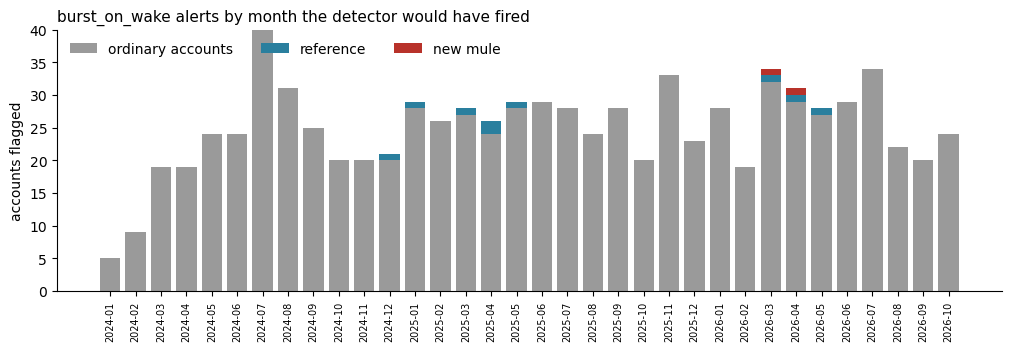

In [9]:
others = scan[scan.group == "other"]
active = others[others.has_activity]
complete = active[active.wake_complete]
def rate(mask, base):
    return f"{int(mask.sum()):,} ({mask.sum() / max(len(base), 1):.1%})"

volume = pd.DataFrame({
    "accounts": [f"{len(others):,}", f"{len(active):,}", f"{len(complete):,}"],
    "burst_on_wake ($50k)": [rate(others.burst_on_wake, others), rate(active.burst_on_wake, active), rate(complete.burst_on_wake, complete)],
    "at $100k": [rate(others.burst_100k, others), rate(active.burst_100k, active), rate(complete.burst_100k, complete)],
    "dormant_then_burst": [rate(others.dormant_then_burst, others), rate(active.dormant_then_burst, active), rate(complete.dormant_then_burst, complete)],
}, index=["all ordinary accounts", "…with real activity", "…with a full 14-day window"])
display(volume)
print("The 200-account sample estimated 5% at $50k and 3.5% at $100k, as a share of accounts at least 180 days old.")

# alerts per month, by the month a nightly detector would have fired
per_month = (scan[scan.burst_on_wake & scan.detect_date.notna()]
               .assign(month=lambda d: d.detect_date.dt.to_period("M"))
               .groupby(["month", "group"]).size().unstack(fill_value=0))
full = per_month.loc[per_month.index < AS_OF.to_period("M")]
print(f"\nAlerts per month (complete months): median {full.sum(axis=1).median():.0f}, max {full.sum(axis=1).max():.0f}")

fig, ax = plt.subplots(figsize=(10, 3.4), constrained_layout=True)
x = per_month.index.astype(str)
ax.bar(x, per_month.get("other", 0), color="#9a9a9a", width=0.8, label="ordinary accounts")
bottom = per_month.get("other", 0)
for g, c in [("reference", "#2a7f9e"), ("new mule", "#b8322a")]:
    if g in per_month:
        ax.bar(x, per_month[g], bottom=bottom, color=c, width=0.8, label=g); bottom = bottom + per_month[g]
ax.set_ylabel("accounts flagged"); ax.set_title("burst_on_wake alerts by month the detector would have fired", loc="left", fontsize=11)
ax.tick_params(axis="x", rotation=90, labelsize=7); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncols=3, loc="upper left")
fig.savefig(OUT / "alerts_per_month.png", dpi=130); plt.show()

**Top of the flagged list.** Ordinary accounts ranked by 14-day turnover, with the biggest flows by narration. These are what
an analyst would see first; narrations show how many are explainable business.

In [10]:
def wake_flows(acid, a, n=3):
    t = tx[(tx.ACID == acid) & (tx.stream == "customer") & (tx.day >= a) & (tx.day < a + WAKE_DAYS)]
    p = (t.TRAN_PARTICULAR.fillna("").str.upper().str.replace(r"^\d+/", "", regex=True)
           .str.replace(r"\d{4,}", "#", regex=True).str.strip().str[:22])
    g = t.assign(p=p).groupby(["p", "dir"]).TRAN_AMT.sum().sort_values(ascending=False).head(n)
    return " | ".join(f"{d} {k} {v / 1e3:,.0f}k" for (k, d), v in g.items())

top = flagged.sort_values("wake_turnover", ascending=False).head(25).copy()
top["wake_$k"] = (top.wake_turnover / 1e3).round(0); top["wake_match"] = top.wake_match.round(2)
top["top_wake_flows"] = [wake_flows(a, int(d)) for a, d in zip(top.ACID, top.awakening_day)]
display(top[["ACCT_NAME", "awakening_day", "wake_$k", "wake_match", "wake_active_days", "dormant_start",
             "detect_date", "top_wake_flows"]])

,ACCT_NAME,awakening_day,wake_$k,wake_match,wake_active_days,dormant_start,detect_date,top_wake_flows
4673,UGANDA NATIONAL OIL COMPANY RBA,21.0,110154.0,0.96,11.0,False,2024-07-18,"dr VITOL PARTIAL PAY 2 IN 32,460k | dr VITOL PARTIAL PAY..."
8306,TOTALENERGIES MARKETING UGANDA LIMITED,161.0,41458.0,1.00,3.0,False,2025-03-13,"dr AGO-UG02-25 PDT-209:26 4,301k | cr AGO-UG02-25 PDT-20..."
15317,CUX TECH-SMC LTD,93.0,11687.0,1.00,11.0,True,2025-10-22,"dr BURTIQUAL 1,334k | cr NEUROLOGY CONSULTANTS 980k | cr..."
18102,KEYSTONE TEXTILES LIMITED,125.0,6550.0,1.00,9.0,True,2026-03-16,dr PAYMENT FOR 914k | cr JOHN SCHUKNECHT 490k | cr PERAZ...
19071,RYX TECH SMC LTD,67.0,6447.0,1.00,10.0,False,2026-02-26,"dr FASBIR 1,633k | dr DADA 911k | cr HU DING 505k"
10261,QUALITY CHEMICAL INDUSTRIES LIMITED,107.0,5882.0,0.90,5.0,True,2025-05-02,"dr # 1,947k | cr /BNF/DIRECTPAYT 1,800k | cr # 1,300k"
18166,KLYO TECH - SMC LIMITED,14.0,5852.0,1.00,11.0,False,2025-11-06,cr KENNETH A JOHNSON 700k | dr TAURARO 453k | dr BURTIQU...
16539,COTTI COFFEE UGANDA LIMITED,23.0,5848.0,0.77,8.0,False,2025-10-20,"cr COTTI COFFEE INTERNATI 2,000k | dr CURRENCY EXCHANGE ..."
14104,ABACUS PHARMA (AFRICA) LIMITED,160.0,5809.0,0.59,5.0,True,2025-12-10,"dr RTGS PMT # ABACUS PHAR 3,656k | cr # DISBURSEMENT CRE..."
3145,GODFREY KIRUMIRA KALULE,55.0,5750.0,0.99,5.0,True,2024-05-31,"cr BANK CHARGES LOAN PAYM 2,817k | dr STI PREMIUM FOR HO..."


## 8. Does production already have them?

In [11]:
# Best effort: compare with the production lead view. Skipped quietly if the view or column isn't there.
try:
    if SYNTHETIC:
        raise RuntimeError("synthetic run")
    leads = pd.read_sql("SELECT * FROM aml_top_leads", rep())
    leads.columns = [c.lower() for c in leads.columns]
    lead_ids = set(leads["acid"].astype(str))
    new_ids = scan.loc[scan.group == "new mule", "ACID"].astype(str)
    print("New mules on the production lead list:", {a: a in lead_ids for a in new_ids})
    print(f"Flagged ordinary accounts also on the production list: {flagged.ACID.astype(str).isin(lead_ids).sum()} of {len(flagged)}")
except Exception as e:
    print(f"Production comparison skipped ({e}). Check the new mules against aml_top_leads by hand.")

Production comparison skipped ('acid'). Check the new mules against aml_top_leads by hand.


## 9. The new mules' timelines

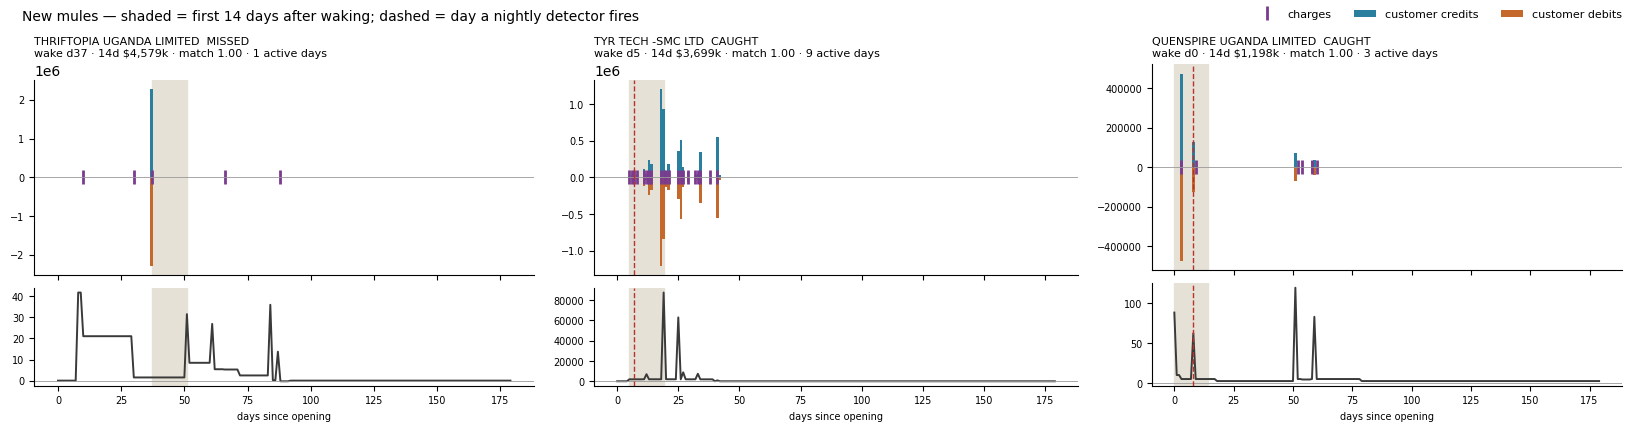

In [12]:
def daily(acid):
    t = tx[tx.ACID == acid]; n = int(obs.get(acid, WINDOW_DAYS))
    piv = (t.assign(col=t.stream + "_" + t.dir)
             .pivot_table(index="day", columns="col", values="TRAN_AMT", aggfunc="sum", fill_value=0))
    d = pd.DataFrame(index=pd.RangeIndex(n, name="day")).join(piv).fillna(0)
    for c in ["customer_cr", "customer_dr", "charge_cr", "charge_dr", "gl_cr", "gl_dr"]:
        if c not in d:
            d[c] = 0.0
    d["balance"] = (d.customer_cr + d.charge_cr + d.gl_cr - d.customer_dr - d.charge_dr - d.gl_dr).cumsum()
    return d

def usd(v):
    return "none" if not v or pd.isna(v) else (f"\\${v / 1e3:,.0f}k" if v >= 1e4 else f"\\${v:,.0f}")

show = scan[scan.group == "new mule"]
if len(show):
    fig = plt.figure(figsize=(5.4 * len(show), 4.2), constrained_layout=True)
    subs = np.atleast_1d(fig.subfigures(1, len(show)))
    for sf, (_, s) in zip(subs, show.iterrows()):
        d = daily(s.ACID)
        ax, axb = sf.subplots(2, 1, sharex=True, gridspec_kw={"height_ratios": [2, 1]})
        ax.bar(d.index, d.customer_cr, color="#2a7f9e", width=1.0, label="customer credits")
        ax.bar(d.index, -d.customer_dr, color="#c4682b", width=1.0, label="customer debits")
        ch = d.index[d.charge_dr > 0]; ax.plot(ch, np.zeros(len(ch)), "|", color="#7a3b8f", ms=10, mew=2, label="charges")
        axb.plot(d.index, d.balance, color="#3a3a3a", lw=1.4)
        for x in (ax, axb):
            x.axhline(0, color="#999", lw=.6); x.spines[["top", "right"]].set_visible(False); x.tick_params(labelsize=7)
            if pd.notna(s.awakening_day):
                x.axvspan(s.awakening_day, s.awakening_day + WAKE_DAYS, color="#e6e1d6", zorder=0)
            if pd.notna(s.first_hit_day):
                x.axvline(s.first_hit_day, color="#b8322a", lw=1, ls="--")
        tag = "CAUGHT" if s.burst_on_wake else "MISSED"
        info = (f"\nwake d{int(s.awakening_day)} · 14d {usd(s.wake_turnover)} · match {s.wake_match:.2f} · "
                f"{int(s.wake_active_days)} active days" if pd.notna(s.awakening_day) else "\nno measurable activity")
        ax.set_title(f"{str(s.ACCT_NAME)[:28]}  {tag}{info}", fontsize=8, loc="left")
        axb.set_xlabel("days since opening", fontsize=7)
    h, l = ax.get_legend_handles_labels()
    fig.legend(h, l, loc="outside upper right", ncols=3, fontsize=8, frameon=False)
    fig.suptitle("New mules — shaded = first 14 days after waking; dashed = day a nightly detector fires",
                 fontsize=10, x=0.01, ha="left")
    fig.savefig(OUT / "new_mules_timelines.png", dpi=130); plt.show()

## 10. Export

In [13]:
scan.to_csv(OUT / "scan_metrics.csv", index=False)
flagged.sort_values("wake_turnover", ascending=False).to_csv(OUT / "scan_flagged.csv", index=False)
new.to_csv(OUT / "new_mules_check.csv", index=False)
volume.to_csv(OUT / "scan_volume.csv")
per_month.to_csv(OUT / "alerts_per_month.csv")
print("Saved to", OUT.resolve())

Saved to /home/A270827/experiments/AML/outputs/early_signals_scan


## 11. Reading the result

| What you see | Reading |
|---|---|
| 2–3 of 3 new mules caught, book rate near 5% | The detector generalises beyond the mules it was tuned on — the strongest evidence so far for phase 2 |
| Caught, but ranked low among hundreds of flags | It finds them, but triage needs a better priority than turnover (narration exclusions, dormancy boost, overlap with production) |
| 1 or 0 caught | The 90% on the original 10 was partly overfit; look at *why* each was missed before changing anything |
| Book rate far above 5% | The 200-account sample under-estimated volume; size the review effort on this number, not the sample |

Also note: `detect_date` vs `IDENTIFIED_ON` is a direct lead-time measure against how business found them. Three mules is
still a small test — read it as direction, and add each new confirmed mule to the next run.

In [14]:
# One-screen summary of the scan, for sharing
print("NEW MULES")
display(new[["ACCT_NAME", "awakening_day", "wake_$k", "wake_match", "wake_active_days", "dormant_start",
             "burst_on_wake", "burst_100k", "detect_date", "rank_of_flagged"]
            + [c for c in ["identified_on", "days_earlier"] if c in new]])
print(f"\nOriginal 10 caught: {int(ref.burst_on_wake.sum())}/{len(ref)} at $50k, {int(ref.burst_100k.sum())} at $100k")
print("\nBOOK VOLUME (ordinary accounts)")
display(volume)
m = full.sum(axis=1)
print(f"Alerts per complete month: median {m.median():.0f}, range {m.min():.0f}-{m.max():.0f}, over {len(m)} months")
print(f"Flagged ordinary accounts that are dormant_then_burst: {int(flagged.dormant_start.sum())} of {len(flagged)}")
print("\nWhat kinds of narration lead the top 50 flagged (first word of the biggest wake flow):")
t50 = flagged.sort_values("wake_turnover", ascending=False).head(50)
kinds = pd.Series([wake_flows(a, int(d), n=1).split(" ")[1:3] for a, d in zip(t50.ACID, t50.awakening_day)]).str.join(" ")
print(kinds.value_counts().head(12).to_string())

NEW MULES


,ACCT_NAME,awakening_day,wake_$k,wake_match,wake_active_days,dormant_start,burst_on_wake,burst_100k,detect_date,rank_of_flagged,identified_on,days_earlier
0,THRIFTOPIA UGANDA LIMITED,37.0,4579.0,1.0,1.0,True,False,False,NaT,—,2026-10-29,NaN
1,TYR TECH -SMC LTD,5.0,3699.0,1.0,9.0,False,True,True,2026-03-05,17 of 849,2026-10-29,238.0
2,QUENSPIRE UGANDA LIMITED,0.0,1198.0,1.0,3.0,False,True,True,2026-04-15,95 of 849,2026-10-29,197.0



Original 10 caught: 9/10 at $50k, 9 at $100k

BOOK VOLUME (ordinary accounts)


,accounts,burst_on_wake ($50k),at $100k,dormant_then_burst
all ordinary accounts,"27,434",838 (3.1%),607 (2.2%),242 (0.9%)
…with real activity,"21,741",838 (3.9%),607 (2.8%),242 (1.1%)
…with a full 14-day window,"21,130",826 (3.9%),597 (2.8%),238 (1.1%)


Alerts per complete month: median 26, range 5-40, over 33 months
Flagged ordinary accounts that are dormant_then_burst: 242 of 838

What kinds of narration lead the top 50 flagged (first word of the biggest wake flow):
# DISBURSEMENT            4
THE UNITED                2
RTGS PMT                  2
AGO-UG02-25 PDT-209:26    1
BURTIQUAL 1,334k          1
FASBIR 1,633k             1
# 1,947k                  1
KENNETH A                 1
COTTI COFFEE              1
BANK CHARGES              1
AGNES YEUNG               1
PAYMENT FOR               1


In [15]:
# Answering BCB: (1) their indicator (i) on the whole book, (2) how much money had arrived when the rule fires
# --- (1) "Minimal or no transactions except fees": customer money in + out below QUIET_MAX_USD in the first N days ---
QUIET_MAX_USD = 1_000
cust = tx[tx.stream == "customer"]
b = pop.set_index("ACID")[["group", "ACCT_NAME", "observed_days"]].copy()
b["is_mule"] = b.group != "other"
rows = []
for n in (30, 60):
    e = b[b.observed_days >= n]                                    # accounts old enough to have had n days
    early = cust[cust.day < n].groupby("ACID").TRAN_AMT.sum().reindex(e.index).fillna(0)
    total = cust.groupby("ACID").TRAN_AMT.sum().reindex(e.index).fillna(0)
    quiet = early < QUIET_MAX_USD
    woke = quiet & (total - early >= WAKE_MIN_USD)              # later moved at least $50k
    o = ~e.is_mule
    rows.append({"quiet for first N days": n,
                 "ordinary accounts flagged": f"{int(quiet[o].sum()):,} of {int(o.sum()):,} ({quiet[o].mean():.0%})",
                 "…of which later moved $50k+": f"{int(woke[o].sum()):,}",
                 "mules flagged": f"{int(quiet[~o].sum())} of {int((~o).sum())}",
                 "which mules": ", ".join(e[quiet & ~o].ACCT_NAME.astype(str).str[:18])})
print(f"BCB INDICATOR (i): less than ${QUIET_MAX_USD:,} of customer money moved in the first N days (fees not counted)")
display(pd.DataFrame(rows).set_index("quiet for first N days"))

# --- (2) Share of each mule's first-180-day credits that arrived AFTER the rule would have fired ---
cr = tx[(tx.stream == "customer") & (tx.dir == "cr")]
def after_share(acid, day):
    c = cr[cr.ACID == acid]; tot = c.TRAN_AMT.sum()
    return (np.nan, tot) if not tot or pd.isna(day) else (1 - c.loc[c.day <= day, "TRAN_AMT"].sum() / tot, tot)
mm = scan[scan.group != "other"].copy()
res = [after_share(a, d) for a, d in zip(mm.ACID, mm.first_hit_day)]
mm["credits_180d_$k"] = [round(t / 1e3) for _, t in res]
mm["credits_after_alert"] = [s for s, _ in res]
print("\nMONEY RECEIVED AFTER THE RULE FIRES (share of first-180-day credits)")
display(mm[["ACCT_NAME", "group", "awakening_day", "first_hit_day", "detect_date", "credits_180d_$k", "credits_after_alert"]]
          .sort_values(["group", "credits_after_alert"]).assign(credits_after_alert=lambda d: (d.credits_after_alert * 100).round(0)))
print(f"Median share of credits that arrived after the alert: {mm.credits_after_alert.median():.0%} "
      f"(mules the rule fired on: {mm.credits_after_alert.notna().sum()} of {len(mm)})")

BCB INDICATOR (i): less than $1,000 of customer money moved in the first N days (fees not counted)


,ordinary accounts flagged,…of which later moved $50k+,mules flagged,which mules
quiet for first N days,,,,
30,"13,756 of 26,600 (52%)",880,5 of 13,"PACIFIC PRINCE INT, EMIC VENTURES, KWELIVEST INVESTME, F..."
60,"11,260 of 25,783 (44%)",415,4 of 13,"PACIFIC PRINCE INT, EMIC VENTURES, KWELIVEST INVESTME, F..."



MONEY RECEIVED AFTER THE RULE FIRES (share of first-180-day credits)


,ACCT_NAME,group,awakening_day,first_hit_day,detect_date,credits_180d_$k,credits_after_alert
21306,QUENSPIRE UGANDA LIMITED,new mule,0.0,8.0,2026-04-15,737,19.0
20410,TYR TECH -SMC LTD,new mule,5.0,7.0,2026-03-05,5074,99.0
20023,THRIFTOPIA UGANDA LIMITED,new mule,37.0,NaN,NaT,2290,NaN
20213,OMOSPIRE UGANDA LIMITED,reference,20.0,29.0,2026-04-08,811,64.0
17571,FRONTIER TEXTILE DEALERS CO LIMITED,reference,142.0,147.0,2026-03-31,1329,92.0
11312,EMIC VENTURES,reference,69.0,74.0,2025-04-22,2252,97.0
11414,KWELIVEST INVESTMENT SMC LIMITED,reference,61.0,64.0,2025-04-25,2811,97.0
9635,HESHIMA PRIME LOGISTICS LTD,reference,21.0,23.0,2025-01-29,5192,98.0
11415,NEBULACORE INNOVATIONS LIMITED,reference,0.0,12.0,2025-03-04,4383,98.0
21910,RAVO TECH COMPANY SMC LIMITED,reference,6.0,11.0,2026-05-20,2683,98.0


Median share of credits that arrived after the alert: 98% (mules the rule fired on: 12 of 13)


In [16]:
o = scan[scan.group == "other"]; print(f"Nightly rule flags {o.first_hit_day.notna().sum():,} ordinary accounts vs {o.burst_on_wake.sum():,} for the 14-day version")

Nightly rule flags 852 ordinary accounts vs 838 for the 14-day version
